# Hausa News Topic Classification (MasakhaNEWS) Full Experiment Notebook

**How to run**
1. `Runtime → Change runtime type → T4 GPU` (needed for the Transformer part).
2. `Runtime → Run all`. When the upload box appears, select all four files: `train.tsv`, `dev.tsv`, `test.tsv`, `labels.txt`.
3. When it finishes, download `results.zip` (all tables and figures) from the last cell.

**Fair-evaluation rule used throughout:** all models are *trained* on train, *selected* by dev macro-F1, and the test set is only used to report final numbers. Never tune on test.

> If a cell asks you to restart the runtime after `pip install`, do it, then use `Runtime → Run all` again.

In [1]:
!pip -q install gensim sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 75.8 MB/s eta 0:00:00


## 1. Setup and configuration

In [2]:
import os, re, time, gc, copy, random, warnings, zipfile, json, platform, shutil
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)
from scipy.stats import binomtest

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# ---------------- CONFIG (edit here) ----------------
SEED         = 42
QUICK_MODE   = False          # True = fewer Transformer experiments (faster)
DATA_DIR     = "/content/data/hau"
OUT_DIR      = "results"
SAVE_MODEL_ZIP = False        # True = also zip the fine-tuned model for download (~1 GB)

# RNN settings
MAX_LEN_RNN = 256
EMB_DIM     = 100
RNN_HIDDEN  = 128
RNN_EPOCHS  = 25
RNN_PATIENCE = 5
RNN_BATCH   = 32
RNN_LR      = 1e-3
# Transformer settings
TR_EPOCHS   = 5
TR_BATCH    = 16
# -----------------------------------------------------

os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RUN_TRANSFORMERS = DEVICE.type == "cuda"

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU")
if not RUN_TRANSFORMERS:
    print("WARNING: no GPU found -> Transformer experiments will be skipped. "
          "Use Runtime > Change runtime type > T4 GPU and run again.")

Device: cuda | Tesla T4


## 2. Load the data
Upload the four files when prompted (they are saved to `DATA_DIR`). If the files are already there, this step is skipped.

In [3]:
needed = ["train.tsv", "dev.tsv", "test.tsv", "labels.txt"]
os.makedirs(DATA_DIR, exist_ok=True)
if not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in needed):
    try:
        from google.colab import files
        print("Select train.tsv, dev.tsv, test.tsv and labels.txt")
        uploaded = files.upload()
        for fn in uploaded:
            clean = re.sub(r" \(\d+\)", "", fn)          # "train (1).tsv" -> "train.tsv"
            shutil.move(fn, os.path.join(DATA_DIR, clean))
    except ImportError:
        raise FileNotFoundError(f"Put {needed} in {DATA_DIR}")
missing = [f for f in needed if not os.path.exists(os.path.join(DATA_DIR, f))]
assert not missing, f"Missing files: {missing}"

train = pd.read_csv(f"{DATA_DIR}/train.tsv", sep="\t")
dev   = pd.read_csv(f"{DATA_DIR}/dev.tsv",   sep="\t")
test  = pd.read_csv(f"{DATA_DIR}/test.tsv",  sep="\t")
LABELS = [l.strip() for l in open(f"{DATA_DIR}/labels.txt").read().splitlines() if l.strip()]
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
N_CLASSES = len(LABELS)

for d in (train, dev, test):
    d["headline"] = d["headline"].fillna("")
    d["text"]     = d["text"].fillna("")
    d["input"]    = d["headline"] + ". " + d["text"]       # model input = headline + body
    d["label"]    = d["category"].map(label2id)
    d["n_words"]  = d["text"].str.split().str.len()
assert train["label"].notna().all() and dev["label"].notna().all() and test["label"].notna().all()
y_train, y_dev, y_test = (d["label"].values.astype(int) for d in (train, dev, test))
splits = {"train": train, "dev": dev, "test": test}

print("Labels:", LABELS)
print({k: v.shape for k, v in splits.items()})
train[["category", "headline", "text"]].head(3)

Select train.tsv, dev.tsv, test.tsv and labels.txt


Saving dev.tsv to dev.tsv
Saving labels.txt to labels.txt
Saving test.tsv to test.tsv
Saving train.tsv to train.tsv
Labels: ['business', 'entertainment', 'health', 'politics', 'religion', 'sports', 'technology']
{'train': (2219, 7), 'dev': (317, 7), 'test': (637, 7)}


,category,headline,text
0,religion,Yadda Shugaban Kungiyar Kirista ya gina masall...,A wani abu da ba a saba gani ba a ƙasa irin Na...
1,entertainment,Burina na zama hamshakiyar 'yar kasuwa – Rayya...,Tauraruwar fina-finan Hausa Surayya Aminu wacc...
2,business,Ƙoƙarin da muke yi na haƙo man fetur a Gombe d...,Shirin Gane Mini Hanya na wannan makon ya tatt...


## 3. Exploratory data analysis (EDA)
Report these findings in the *Dataset* section: size, class balance, text length, duplicates / leakage, short articles, and vocabulary coverage.

Split sizes: {'train': 2219, 'dev': 317, 'test': 637}
Duplicate rows in train: 0
Overlap train/dev: urls=0, identical texts=0
Overlap train/test: urls=0, identical texts=1
Overlap dev/test: urls=0, identical texts=0


count          percent            
              train dev test   train   dev  test
category                                        
business        279  40   80    12.6  12.6  12.6
entertainment   350  50  100    15.8  15.8  15.7
health          345  49   99    15.5  15.5  15.5
politics        350  50  100    15.8  15.8  15.7
religion        345  49   99    15.5  15.5  15.5
sports          347  50  100    15.6  15.8  15.7
technology      203  29   59     9.1   9.1   9.3

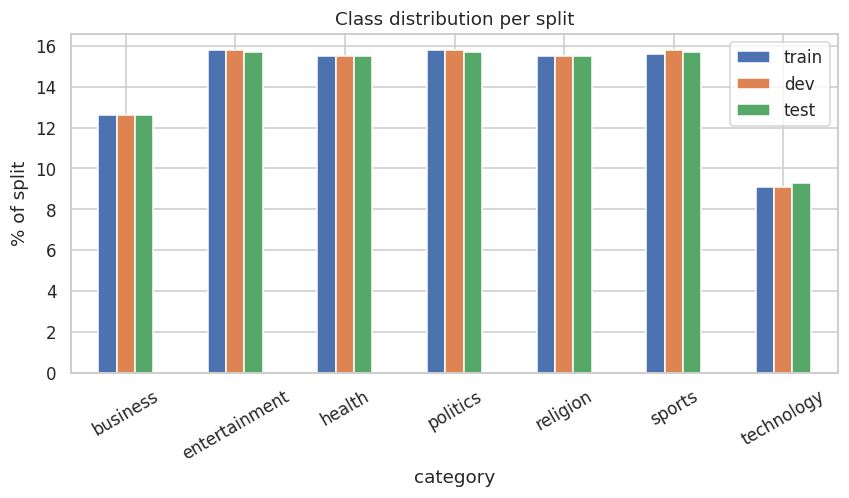

Imbalance ratio (largest/smallest class in train): 1.72


In [4]:
TOKEN_RE = re.compile(r"\w+(?:['’]\w+)*", re.UNICODE)    # \w keeps Hausa letters such as ɓ ɗ ƙ ƴ
def tokenize(s): return TOKEN_RE.findall(s.lower())

# --- sizes, nulls, duplicates
print("Split sizes:", {k: len(v) for k, v in splits.items()})
print("Duplicate rows in train:", train.duplicated(subset=["headline", "text"]).sum())

# --- leakage checks between splits
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    url_overlap  = len(set(splits[a]["url"]) & set(splits[b]["url"]))
    text_overlap = len(set(splits[a]["text"]) & set(splits[b]["text"]))
    print(f"Overlap {a}/{b}: urls={url_overlap}, identical texts={text_overlap}")

# --- class distribution
dist = pd.DataFrame({k: v["category"].value_counts() for k, v in splits.items()}).reindex(LABELS)
dist_pct = (dist / dist.sum() * 100).round(1)
display(pd.concat({"count": dist, "percent": dist_pct}, axis=1))

fig, ax = plt.subplots(figsize=(9, 4))
dist_pct.plot(kind="bar", ax=ax)
ax.set_ylabel("% of split"); ax.set_title("Class distribution per split"); plt.xticks(rotation=30)
plt.savefig(f"{OUT_DIR}/fig_class_distribution.png", dpi=200, bbox_inches="tight"); plt.show()
print("Imbalance ratio (largest/smallest class in train): %.2f" % (dist["train"].max() / dist["train"].min()))

count    2219.0
mean      437.3
std       392.9
min         2.0
25%       164.0
50%       334.0
75%       594.5
max      2940.0
Name: n_words, dtype: float64


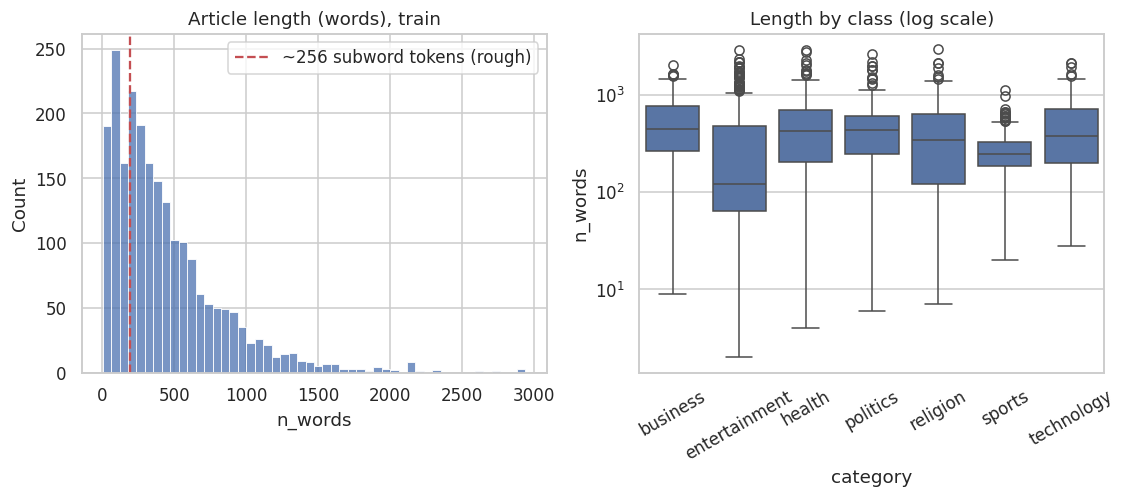

Articles with <20 words in train: 57


,category,headline,text
9,entertainment,Hotunan Afirka na mako: Daga 4 zuwa 10 ga wata...,Zababbun hotunan Afirka da 'yan nahiyar a wasu...
22,entertainment,'Waƙar 'Dama','Waƙar 'Dama'
53,politics,Kai-tsaye: Sakamakon zaɓen gwamnan jihar Edo,Ku duba yadda sakamakon zaben gwamnan jihar Ed...
79,entertainment,...Daga Bakin Mai Ita tare da Mika'il Bin Hassan,Daga Bakin Mai Ita tare da Mika'il Bin Hassan
86,entertainment,Kayatattun hotunan Afirka na wannan makon: Dag...,Zaɓaɓɓun hotunan abubuwan da suka faru a Afirk...


In [5]:
# --- text length
print(train["n_words"].describe().round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["n_words"], bins=50, ax=axes[0]); axes[0].set_title("Article length (words), train")
axes[0].axvline(256 * 0.75, color="r", ls="--", label="~256 subword tokens (rough)"); axes[0].legend()
sns.boxplot(data=train, x="category", y="n_words", order=LABELS, ax=axes[1])
axes[1].set_yscale("log"); axes[1].set_title("Length by class (log scale)"); plt.setp(axes[1].get_xticklabels(), rotation=30)
plt.savefig(f"{OUT_DIR}/fig_length_distribution.png", dpi=200, bbox_inches="tight"); plt.show()

short = train[train["n_words"] < 20]
print(f"Articles with <20 words in train: {len(short)}")
display(short[["category", "headline", "text"]].head(5))

In [6]:
# --- vocabulary statistics and out-of-vocabulary (OOV) rate
train_tok = [tokenize(s) for s in train["input"]]
dev_tok   = [tokenize(s) for s in dev["input"]]
test_tok  = [tokenize(s) for s in test["input"]]
counter   = Counter(t for toks in train_tok for t in toks)
train_vocab = set(counter)
n_tokens, n_types = sum(counter.values()), len(counter)
hapax = sum(1 for c in counter.values() if c == 1)
print(f"Train tokens: {n_tokens:,} | vocabulary (types): {n_types:,} | hapax legomena: {hapax:,} ({hapax/n_types:.1%} of types)")
def oov_rate(tok_lists):
    all_t = [t for toks in tok_lists for t in toks]
    return np.mean([t not in train_vocab for t in all_t])
print(f"OOV token rate vs train vocab -> dev: {oov_rate(dev_tok):.2%}, test: {oov_rate(test_tok):.2%}")

Train tokens: 1,002,760 | vocabulary (types): 30,402 | hapax legomena: 13,833 (45.5% of types)
OOV token rate vs train vocab -> dev: 2.00%, test: 2.43%


## 4. Experiment tracking utilities
Every experiment is logged to one table (`experiment_results.csv`). **Selection = dev macro-F1. Test numbers are reported only.**
Macro-F1 is the main metric because the classes are imbalanced (technology is the smallest); accuracy alone would hide weak classes.

In [7]:
def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return dict(accuracy=accuracy_score(y_true, y_pred), macro_precision=p, macro_recall=r, macro_f1=f,
                weighted_f1=f1_score(y_true, y_pred, average="weighted"))

results, preds, histories, objects = [], {}, {}, {}

def log_experiment(exp_id, family, name, params, dev_pred, test_pred, test_proba=None, train_time=np.nan):
    dm, tm = compute_metrics(y_dev, dev_pred), compute_metrics(y_test, test_pred)
    results.append({"exp_id": exp_id, "family": family, "name": name, "params": json.dumps(params),
                    "dev_accuracy": dm["accuracy"], "dev_macro_f1": dm["macro_f1"],
                    "test_accuracy": tm["accuracy"], "test_macro_precision": tm["macro_precision"],
                    "test_macro_recall": tm["macro_recall"], "test_macro_f1": tm["macro_f1"],
                    "test_weighted_f1": tm["weighted_f1"], "train_time_s": round(train_time, 1)})
    preds[exp_id] = dict(dev=np.asarray(dev_pred), test=np.asarray(test_pred), proba=test_proba)
    print(f"[{exp_id}] {name[:52]:<52} dev F1={dm['macro_f1']:.4f} | test acc={tm['accuracy']:.4f}  test macro-F1={tm['macro_f1']:.4f}")

## 5. Sparse models (baseline + classical experiments)
**Baseline (S1):** TF-IDF word uni+bigrams + Logistic Regression. It is fast, strong on topic classification, and gives a number the neural models must beat.

| ID | Question it answers |
|---|---|
| S1 → S2 | Does a weaker regularisation (C=10) help? |
| S2 → S3, S4 | Is Logistic Regression the right classifier (vs SVM, Naive Bayes)? |
| S2 → S5 | Do character n-grams help with Hausa spelling variation / rich morphology? |
| S2 → S6, S7 | Which part carries the signal: headline only, or body only? |

In [8]:
def run_sparse(exp_id, name, vec, clf, text_fn=lambda d: d["input"], params=None):
    t0 = time.time()
    Xtr = vec.fit_transform(text_fn(train)); Xdv = vec.transform(text_fn(dev)); Xte = vec.transform(text_fn(test))
    clf.fit(Xtr, y_train)
    proba = clf.predict_proba(Xte) if hasattr(clf, "predict_proba") else None
    log_experiment(exp_id, "Sparse", name, params or {}, clf.predict(Xdv), clf.predict(Xte), proba, time.time() - t0)
    objects[exp_id] = (vec, clf)

word_vec = lambda: TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2)

run_sparse("S1", "TF-IDF word(1-2) + LogReg C=1 [BASELINE]", word_vec(),
           LogisticRegression(max_iter=1000, class_weight="balanced"), params=dict(C=1, ngram="1-2", input="headline+body"))
run_sparse("S2", "TF-IDF word(1-2) + LogReg C=10", word_vec(),
           LogisticRegression(max_iter=1000, C=10, class_weight="balanced"), params=dict(C=10))
run_sparse("S3", "TF-IDF word(1-2) + LinearSVC", word_vec(),
           LinearSVC(class_weight="balanced"), params=dict(C=1))
run_sparse("S4", "TF-IDF word(1-2) + Multinomial NB", word_vec(),
           MultinomialNB(alpha=0.1), params=dict(alpha=0.1))
run_sparse("S5", "TF-IDF char_wb(2-5) + LogReg C=10",
           TfidfVectorizer(sublinear_tf=True, analyzer="char_wb", ngram_range=(2, 5), min_df=2, max_features=200000),
           LogisticRegression(max_iter=1000, C=10, class_weight="balanced"), params=dict(C=10, analyzer="char_wb 2-5"))
run_sparse("S6", "Headline ONLY: TF-IDF word + LogReg C=10", word_vec(),
           LogisticRegression(max_iter=1000, C=10, class_weight="balanced"), text_fn=lambda d: d["headline"], params=dict(input="headline"))
run_sparse("S7", "Body ONLY: TF-IDF word + LogReg C=10", word_vec(),
           LogisticRegression(max_iter=1000, C=10, class_weight="balanced"), text_fn=lambda d: d["text"], params=dict(input="body"))

[S1] TF-IDF word(1-2) + LogReg C=1 [BASELINE]             dev F1=0.8893 | test acc=0.8807  test macro-F1=0.8713
[S2] TF-IDF word(1-2) + LogReg C=10                       dev F1=0.9089 | test acc=0.8932  test macro-F1=0.8854
[S3] TF-IDF word(1-2) + LinearSVC                         dev F1=0.9022 | test acc=0.8948  test macro-F1=0.8844
[S4] TF-IDF word(1-2) + Multinomial NB                    dev F1=0.8609 | test acc=0.8556  test macro-F1=0.8279
[S5] TF-IDF char_wb(2-5) + LogReg C=10                    dev F1=0.8936 | test acc=0.8917  test macro-F1=0.8830
[S6] Headline ONLY: TF-IDF word + LogReg C=10             dev F1=0.8165 | test acc=0.7991  test macro-F1=0.7897
[S7] Body ONLY: TF-IDF word + LogReg C=10                 dev F1=0.8943 | test acc=0.8823  test macro-F1=0.8717


## 6. Neural models: BiLSTM / BiGRU with Word2Vec embeddings
**Pipeline:** regex tokenizer → vocabulary from *train only* (min freq 2) → each article truncated/padded to 256 tokens → embedding layer → bidirectional LSTM/GRU → pooling over time steps → dropout → linear layer → softmax. Loss = class-weighted cross-entropy, Adam, gradient clipping, early stopping on dev macro-F1.

**Word2Vec** (skip-gram, 100-d) is trained **only on the training articles**, so no dev/test text leaks in.

| ID | Question it answers |
|---|---|
| N1 vs N2 | Do pretrained (Word2Vec) embeddings beat randomly initialised ones? |
| N2 vs N3 | LSTM vs GRU |
| N3 vs N4 | Does attention pooling beat max pooling? |

In [9]:
# ---- vocabulary & encoding
itos = ["<pad>", "<unk>"] + [w for w, c in counter.most_common() if c >= 2]
stoi = {w: i for i, w in enumerate(itos)}
print("RNN vocabulary size:", len(itos))

def encode_all(tok_lists):
    X = torch.zeros((len(tok_lists), MAX_LEN_RNN), dtype=torch.long); L = torch.zeros(len(tok_lists), dtype=torch.long)
    for i, toks in enumerate(tok_lists):
        ids = [stoi.get(t, 1) for t in toks[:MAX_LEN_RNN]] or [1]
        X[i, :len(ids)] = torch.tensor(ids); L[i] = len(ids)
    return X, L
Xtr_r, Ltr_r = encode_all(train_tok); Xdv_r, Ldv_r = encode_all(dev_tok); Xte_r, Lte_r = encode_all(test_tok)
print("Share of train articles truncated at %d tokens: %.1f%%" % (MAX_LEN_RNN, 100 * np.mean([len(t) > MAX_LEN_RNN for t in train_tok])))

# ---- Word2Vec (train text only)
emb_matrix = None
try:
    from gensim.models import Word2Vec
    t0 = time.time()
    w2v = Word2Vec(sentences=train_tok, vector_size=EMB_DIM, window=5, min_count=2, sg=1, workers=1, epochs=30, seed=SEED)
    emb_matrix = np.random.normal(0, 0.1, (len(itos), EMB_DIM)).astype("float32"); emb_matrix[0] = 0
    for i, w in enumerate(itos):
        if w in w2v.wv: emb_matrix[i] = w2v.wv[w]
    print(f"Word2Vec trained in {time.time()-t0:.0f}s on {n_tokens:,} tokens")
    for w in itos[100:104]:                                           # sanity check: nearest neighbours
        print(f"  {w!r} -> {[x for x, _ in w2v.wv.most_similar(w, topn=5)]}")
except Exception as e:
    print("Word2Vec unavailable (", e, ") -> experiments N2-N4 will be skipped. Restart runtime after the pip install and run again.")

RNN vocabulary size: 16571
Share of train articles truncated at 256 tokens: 62.1%
Word2Vec trained in 184s on 1,002,760 tokens
  'daya' -> ['ɗaya', 'shikan', 'shika', 'ginshikan', 'hudu']
  'samun' -> ['samu', 'wagegen', 'hanata', 'yain', 'sami']
  'fi' -> ['mafi', 'dacewa', 'owner', "nata'ala", 'mafiya']
  'dama' -> ['wasu', 'yawa', 'kyautatu', 'sirranta', 'daban']


In [10]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden, n_classes, cell="lstm", pooling="max",
                 dropout=0.4, emb_matrix=None):
        super().__init__()
        self.pooling = pooling
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        if emb_matrix is not None:
            self.emb.weight.data.copy_(torch.tensor(emb_matrix))
        rnn_cls = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn_cls(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.att = nn.Linear(2 * hidden, 1)                           # used only for attention pooling
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden, n_classes)

    def forward(self, x, lengths):
        mask = x != 0                                                 # (B, T) True for real tokens
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))   # (B, T, 2H)
        if self.pooling == "attn":                                    # additive attention over time steps
            scores = self.att(out).squeeze(-1).masked_fill(~mask, -1e9)
            w = torch.softmax(scores, dim=-1).unsqueeze(-1)
            pooled = (out * w).sum(1)
        else:                                                         # masked max-pooling
            pooled = out.masked_fill(~mask.unsqueeze(-1), -1e9).max(1).values
        return self.fc(self.drop(pooled))

@torch.no_grad()
def rnn_proba(model, X, L, bs=128):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(torch.softmax(model(X[i:i+bs].to(DEVICE), L[i:i+bs]), -1).cpu())
    return torch.cat(out).numpy()

def run_rnn(exp_id, name, cell="lstm", pooling="max", use_w2v=False):
    set_seed(SEED); t0 = time.time()
    model = RNNClassifier(len(itos), EMB_DIM, RNN_HIDDEN, N_CLASSES, cell, pooling,
                          emb_matrix=emb_matrix if use_w2v else None).to(DEVICE)
    cw = torch.tensor(len(y_train) / (N_CLASSES * np.bincount(y_train)), dtype=torch.float32).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=cw)
    opt = torch.optim.Adam(model.parameters(), lr=RNN_LR)
    ytr = torch.tensor(y_train)
    best_f1, best_state, best_ep, bad = -1, None, 0, 0
    hist = {"train_loss": [], "dev_f1": []}
    for ep in range(1, RNN_EPOCHS + 1):
        model.train(); perm = torch.randperm(len(Xtr_r)); tot = 0
        for i in range(0, len(perm), RNN_BATCH):
            idx = perm[i:i + RNN_BATCH]
            opt.zero_grad()
            loss = loss_fn(model(Xtr_r[idx].to(DEVICE), Ltr_r[idx]), ytr[idx].to(DEVICE))
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(idx)
        dev_f1 = f1_score(y_dev, rnn_proba(model, Xdv_r, Ldv_r).argmax(1), average="macro")
        hist["train_loss"].append(tot / len(perm)); hist["dev_f1"].append(dev_f1)
        if dev_f1 > best_f1: best_f1, best_ep, bad = dev_f1, ep, 0; best_state = copy.deepcopy(model.state_dict())
        else: bad += 1
        if bad >= RNN_PATIENCE: break
    model.load_state_dict(best_state)
    pd_, pt_ = rnn_proba(model, Xdv_r, Ldv_r), rnn_proba(model, Xte_r, Lte_r)
    histories[exp_id] = hist
    log_experiment(exp_id, "RNN", name, dict(cell=cell, pooling=pooling, w2v=use_w2v, hidden=RNN_HIDDEN, best_epoch=best_ep, max_len=MAX_LEN_RNN),
                   pd_.argmax(1), pt_.argmax(1), pt_, time.time() - t0)
    del model, opt; gc.collect(); torch.cuda.empty_cache()

run_rnn("N1", "BiLSTM + random embeddings + max-pool", "lstm", "max", use_w2v=False)
if emb_matrix is not None:
    run_rnn("N2", "BiLSTM + Word2Vec + max-pool", "lstm", "max", use_w2v=True)
    run_rnn("N3", "BiGRU  + Word2Vec + max-pool", "gru", "max", use_w2v=True)
    run_rnn("N4", "BiGRU  + Word2Vec + attention pooling", "gru", "attn", use_w2v=True)

[N1] BiLSTM + random embeddings + max-pool                dev F1=0.8370 | test acc=0.8100  test macro-F1=0.7996
[N2] BiLSTM + Word2Vec + max-pool                         dev F1=0.9050 | test acc=0.8964  test macro-F1=0.8882
[N3] BiGRU  + Word2Vec + max-pool                         dev F1=0.8953 | test acc=0.8854  test macro-F1=0.8708
[N4] BiGRU  + Word2Vec + attention pooling                dev F1=0.9062 | test acc=0.8964  test macro-F1=0.8839


## 7. Transformer fine-tuning (Hugging Face)
**Approach:** pretrained encoder + a classification head on the `[CLS]`/`<s>` representation, fine-tuned end-to-end with AdamW, linear warm-up/decay, fp16 mixed precision, class-weighted cross-entropy, gradient clipping. The best epoch (by dev macro-F1) is kept. The training loop is written by hand (not `Trainer`) so every step is visible and explainable in your video.

| ID | Question it answers |
|---|---|
| T1 vs T4 | Does an Africa-focused model (AfroXLMR) beat generic multilingual XLM-R? |
| T2 vs T4 | AfroXLMR vs AfriBERTa (a smaller model pretrained only on African languages) |
| T3, T4, T5 | How much does max sequence length (128 / 256 / 512) matter, given long articles? |
| T4 vs T6 | Learning-rate sensitivity (2e-5 vs 5e-5) |
| T4 vs T7 | Is full fine-tuning needed, or is a frozen encoder + trained head enough? |

*Note: AfriBERTa uses its recommended higher learning rate (5e-5), so T2 differs from T4 in both model and LR — mention this when you discuss it.*

In [11]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

BEST_TR = {"dev_f1": -1.0, "exp_id": None, "max_len": None, "model_name": None}

def make_batch(ids_list, idx, pad_id):
    L = max(len(ids_list[j]) for j in idx)
    x = torch.full((len(idx), L), pad_id, dtype=torch.long); m = torch.zeros((len(idx), L), dtype=torch.long)
    for r, j in enumerate(idx):
        s = ids_list[j]; x[r, :len(s)] = torch.tensor(s); m[r, :len(s)] = 1
    return x, m

@torch.no_grad()
def tr_proba(model, ids_list, pad_id, bs=64):
    model.eval(); order = np.argsort([len(s) for s in ids_list]); out = np.zeros((len(ids_list), N_CLASSES), dtype="float32")
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]; x, m = make_batch(ids_list, idx, pad_id)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = model(input_ids=x.to(DEVICE), attention_mask=m.to(DEVICE)).logits
        out[idx] = torch.softmax(logits.float(), -1).cpu().numpy()
    return out

def run_transformer(exp_id, name, model_name, max_len=256, lr=2e-5, epochs=TR_EPOCHS, bs=TR_BATCH,
                    weight_decay=0.01, warmup_ratio=0.1, freeze_encoder=False):
    set_seed(SEED); t0 = time.time()
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=N_CLASSES, id2label=id2label, label2id=label2id).to(DEVICE)
    if freeze_encoder:
        for p in model.base_model.parameters(): p.requires_grad = False
    enc = {k: tok(list(d["input"]), truncation=True, max_length=max_len)["input_ids"] for k, d in splits.items()}
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 0
    trunc_rate = float(np.mean([len(s) >= max_len for s in enc["train"]]))

    trainable = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    no_decay = ("bias", "LayerNorm.weight")
    opt = torch.optim.AdamW([
        {"params": [p for n, p in trainable if not any(nd in n for nd in no_decay)], "weight_decay": weight_decay},
        {"params": [p for n, p in trainable if any(nd in n for nd in no_decay)], "weight_decay": 0.0}], lr=lr)
    steps_per_epoch = int(np.ceil(len(y_train) / bs)); total = steps_per_epoch * epochs
    warm = int(warmup_ratio * total)
    # linear warm-up for `warm` steps, then linear decay to 0
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: s / max(1, warm) if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    cw = torch.tensor(len(y_train) / (N_CLASSES * np.bincount(y_train)), dtype=torch.float32).to(DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=cw)

    best_f1, best_state, best_ep = -1, None, 0
    hist = {"train_loss": [], "dev_f1": []}
    for ep in range(1, epochs + 1):
        model.train(); perm = np.random.permutation(len(y_train)); tot = 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; x, m = make_batch(enc["train"], idx, pad_id)
            y = torch.tensor(y_train[idx]).to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=x.to(DEVICE), attention_mask=m.to(DEVICE)).logits
            loss = loss_fn(logits.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_([p for _, p in trainable], 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(idx)
        dev_f1 = f1_score(y_dev, tr_proba(model, enc["dev"], pad_id).argmax(1), average="macro")
        hist["train_loss"].append(tot / len(perm)); hist["dev_f1"].append(dev_f1)
        print(f"   [{exp_id}] epoch {ep}/{epochs}  train loss {tot/len(perm):.4f}  dev macro-F1 {dev_f1:.4f}")
        if dev_f1 > best_f1:
            best_f1, best_ep = dev_f1, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    pd_, pt_ = tr_proba(model, enc["dev"], pad_id), tr_proba(model, enc["test"], pad_id)
    histories[exp_id] = hist
    log_experiment(exp_id, "Transformer", name,
                   dict(model=model_name, max_len=max_len, lr=lr, epochs=epochs, batch=bs, frozen=freeze_encoder,
                        best_epoch=best_ep, train_trunc_rate=round(trunc_rate, 3)),
                   pd_.argmax(1), pt_.argmax(1), pt_, time.time() - t0)
    if best_f1 > BEST_TR["dev_f1"]:                                   # keep the best fine-tuned model on disk for deployment
        model.save_pretrained("best_model"); tok.save_pretrained("best_model")
        BEST_TR.update(dev_f1=best_f1, exp_id=exp_id, max_len=max_len, model_name=model_name)
    del model, opt, best_state; gc.collect(); torch.cuda.empty_cache()

AFRO = "Davlan/afro-xlmr-base"
TR_EXPERIMENTS = [
    dict(exp_id="T4", name="AfroXLMR-base len256 lr2e-5", model_name=AFRO, max_len=256, lr=2e-5),
    dict(exp_id="T2", name="AfriBERTa-base len256 lr5e-5", model_name="castorini/afriberta_base", max_len=256, lr=5e-5),
    dict(exp_id="T1", name="XLM-R-base (generic) len256 lr2e-5", model_name="xlm-roberta-base", max_len=256, lr=2e-5),
    dict(exp_id="T3", name="AfroXLMR-base len128 lr2e-5", model_name=AFRO, max_len=128, lr=2e-5),
    dict(exp_id="T5", name="AfroXLMR-base len512 lr2e-5 (bs8)", model_name=AFRO, max_len=512, lr=2e-5, bs=8),
    dict(exp_id="T6", name="AfroXLMR-base len256 lr5e-5", model_name=AFRO, max_len=256, lr=5e-5),
    dict(exp_id="T7", name="AfroXLMR-base FROZEN encoder len256 lr1e-3", model_name=AFRO, max_len=256, lr=1e-3, epochs=8, freeze_encoder=True),
]
if QUICK_MODE:
    TR_EXPERIMENTS = [e for e in TR_EXPERIMENTS if e["exp_id"] in ("T4", "T2")]

if RUN_TRANSFORMERS:
    for cfg in TR_EXPERIMENTS:
        print(f"\n=== {cfg['exp_id']}: {cfg['name']} ===")
        try:
            run_transformer(**cfg)
        except Exception as e:                                        # one failed model must not stop the notebook
            print(f"!! {cfg['exp_id']} FAILED: {type(e).__name__}: {str(e)[:300]}")
            gc.collect(); torch.cuda.empty_cache()
else:
    print("Skipped (no GPU).")


=== T4: AfroXLMR-base len256 lr2e-5 ===


config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

...

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   [T6] epoch 1/5  train loss 0.9984  dev macro-F1 0.8413
   [T6] epoch 2/5  train loss 0.2811  dev macro-F1 0.9059
   [T6] epoch 3/5  train loss 0.1223  dev macro-F1 0.8920
   [T6] epoch 4/5  train loss 0.0527  dev macro-F1 0.9046
   [T6] epoch 5/5  train loss 0.0139  dev macro-F1 0.9158
[T6] AfroXLMR-base len256 lr5e-5                          dev F1=0.9158 | test acc=0.9121  test macro-F1=0.9060

=== T7: AfroXLMR-base FROZEN encoder len256 lr1e-3 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


   [T7] epoch 1/8  train loss 1.4104  dev macro-F1 0.5720
   [T7] epoch 2/8  train loss 0.7676  dev macro-F1 0.7687
   [T7] epoch 3/8  train loss 0.7064  dev macro-F1 0.7615
   [T7] epoch 4/8  train loss 0.6247  dev macro-F1 0.8061
   [T7] epoch 5/8  train loss 0.5612  dev macro-F1 0.8157
   [T7] epoch 6/8  train loss 0.5590  dev macro-F1 0.8243
   [T7] epoch 7/8  train loss 0.5101  dev macro-F1 0.8252
   [T7] epoch 8/8  train loss 0.4729  dev macro-F1 0.8390
[T7] AfroXLMR-base FROZEN encoder len256 lr1e-3           dev F1=0.8390 | test acc=0.8210  test macro-F1=0.8075


## 8. Results: experiment table, comparison chart, learning curves

All experiments, sorted by DEV macro-F1 (the selection criterion):


,exp_id,family,name,dev_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,train_time_s
0,T5,Transformer,AfroXLMR-base len512 lr2e-5 (bs8),0.9159,0.9137,0.9089,0.9080,0.9077,458.2
1,T6,Transformer,AfroXLMR-base len256 lr5e-5,0.9158,0.9121,0.9086,0.9050,0.9060,220.1
2,S2,Sparse,TF-IDF word(1-2) + LogReg C=10,0.9089,0.8932,0.8856,0.8866,0.8854,16.5
3,N4,RNN,BiGRU + Word2Vec + attention pooling,0.9062,0.8964,0.8848,0.8839,0.8839,20.3
4,N2,RNN,BiLSTM + Word2Vec + max-pool,0.9050,0.8964,0.8880,0.8898,0.8882,31.6
5,T2,Transformer,AfriBERTa-base len256 lr5e-5,0.9037,0.9152,0.9102,0.9091,0.9095,161.4
6,S3,Sparse,TF-IDF word(1-2) + LinearSVC,0.9022,0.8948,0.8870,0.8844,0.8844,3.4
7,T4,Transformer,AfroXLMR-base len256 lr2e-5,0.9014,0.9105,0.9032,0.9057,0.9029,231.5
8,N3,RNN,BiGRU + Word2Vec + max-pool,0.8953,0.8854,0.8791,0.8703,0.8708,40.5
9,S7,Sparse,Body ONLY: TF-IDF word + LogReg C=10,0.8943,0.8823,0.8731,0.8719,0.8717,11.7


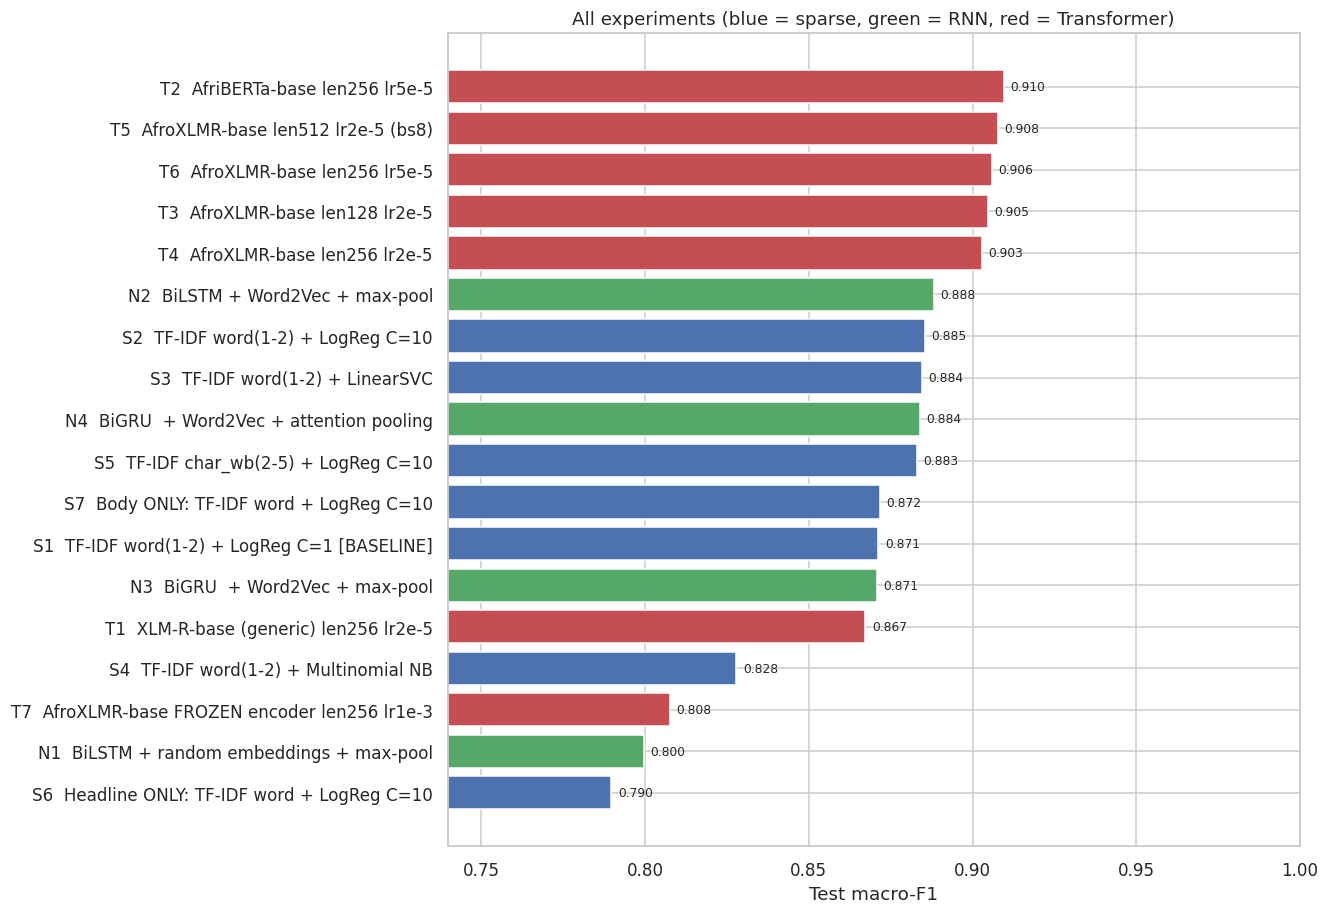


Best by dev macro-F1: T5 (AfroXLMR-base len512 lr2e-5 (bs8))
Baseline test macro-F1 = 0.8713 | Best test macro-F1 = 0.9077


In [12]:
res = pd.DataFrame(results)
res.to_csv(f"{OUT_DIR}/experiment_results.csv", index=False)
res_sorted = res.sort_values("dev_macro_f1", ascending=False).reset_index(drop=True)
cols = ["exp_id", "family", "name", "dev_macro_f1", "test_accuracy", "test_macro_precision", "test_macro_recall", "test_macro_f1", "train_time_s"]
print("All experiments, sorted by DEV macro-F1 (the selection criterion):")
display(res_sorted[cols].round(4))

# --- comparison chart
order = res.sort_values("test_macro_f1")
palette = {"Sparse": "#4C72B0", "RNN": "#55A868", "Transformer": "#C44E52"}
fig, ax = plt.subplots(figsize=(10, 0.45 * len(order) + 1.5))
ax.barh(order["exp_id"] + "  " + order["name"].str[:42], order["test_macro_f1"], color=[palette[f] for f in order["family"]])
for y, v in enumerate(order["test_macro_f1"]): ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(max(0, order["test_macro_f1"].min() - 0.05), 1.0); ax.set_xlabel("Test macro-F1")
ax.set_title("All experiments (blue = sparse, green = RNN, red = Transformer)")
plt.savefig(f"{OUT_DIR}/fig_experiment_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

best_id = res_sorted.iloc[0]["exp_id"]; baseline_id = "S1"
print(f"\nBest by dev macro-F1: {best_id} ({res_sorted.iloc[0]['name']})")
print(f"Baseline test macro-F1 = {res.loc[res.exp_id==baseline_id,'test_macro_f1'].item():.4f} | "
      f"Best test macro-F1 = {res_sorted.iloc[0]['test_macro_f1']:.4f}")

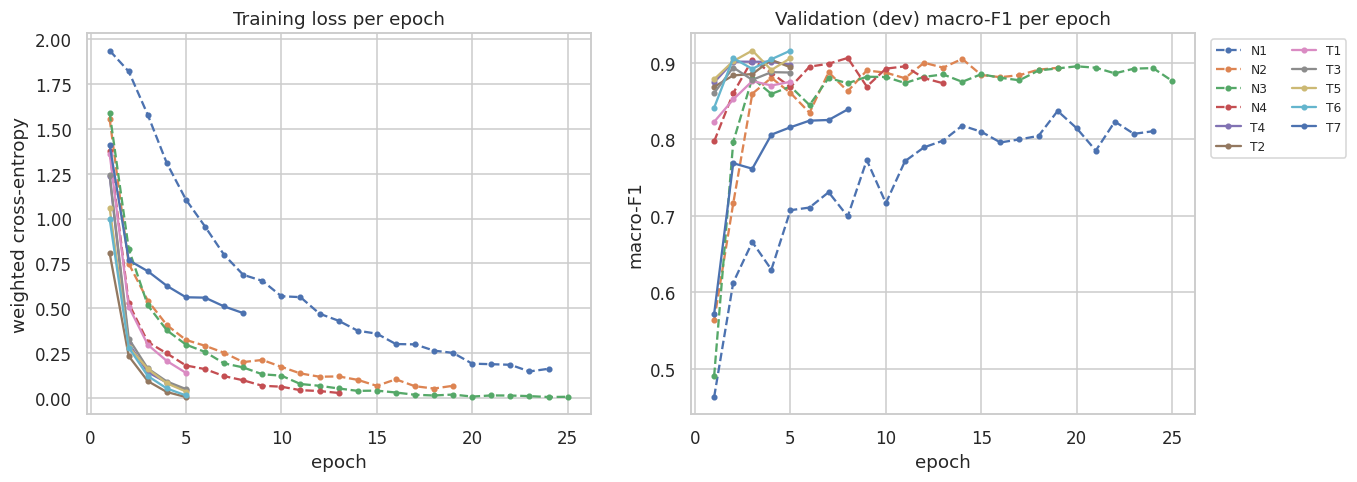

In [13]:
# --- learning curves (neural + Transformer runs)
if histories:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for eid, h in histories.items():
        ls = "-" if eid.startswith("T") else "--"
        axes[0].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], ls, marker="o", ms=3, label=eid)
        axes[1].plot(range(1, len(h["dev_f1"]) + 1), h["dev_f1"], ls, marker="o", ms=3, label=eid)
    axes[0].set_title("Training loss per epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("weighted cross-entropy")
    axes[1].set_title("Validation (dev) macro-F1 per epoch"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("macro-F1")
    axes[1].legend(ncol=2, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.savefig(f"{OUT_DIR}/fig_learning_curves.png", dpi=200, bbox_inches="tight"); plt.show()

## 9. Final evaluation of the baseline vs the best model
Per-class precision / recall / F1, normalised confusion matrices, and a per-class F1 comparison.

S1: TF-IDF word(1-2) + LogReg C=1 [BASELINE]  (TEST SET)
               precision    recall  f1-score   support

     business      0.769     0.750     0.759        80
entertainment      0.925     0.860     0.891       100
       health      0.893     0.929     0.911        99
     politics      0.890     0.890     0.890       100
     religion      0.918     0.899     0.908        99
       sports      1.000     0.960     0.980       100
   technology      0.700     0.831     0.760        59

     accuracy                          0.881       637
    macro avg      0.871     0.874     0.871       637
 weighted avg      0.885     0.881     0.882       637

T5: AfroXLMR-base len512 lr2e-5 (bs8)  (TEST SET)
               precision    recall  f1-score   support

     business      0.878     0.812     0.844        80
entertainment      0.925     0.860     0.891       100
       health      0.941     0.960     0.950        99
     politics      0.864     0.950     0.905       100
     reli

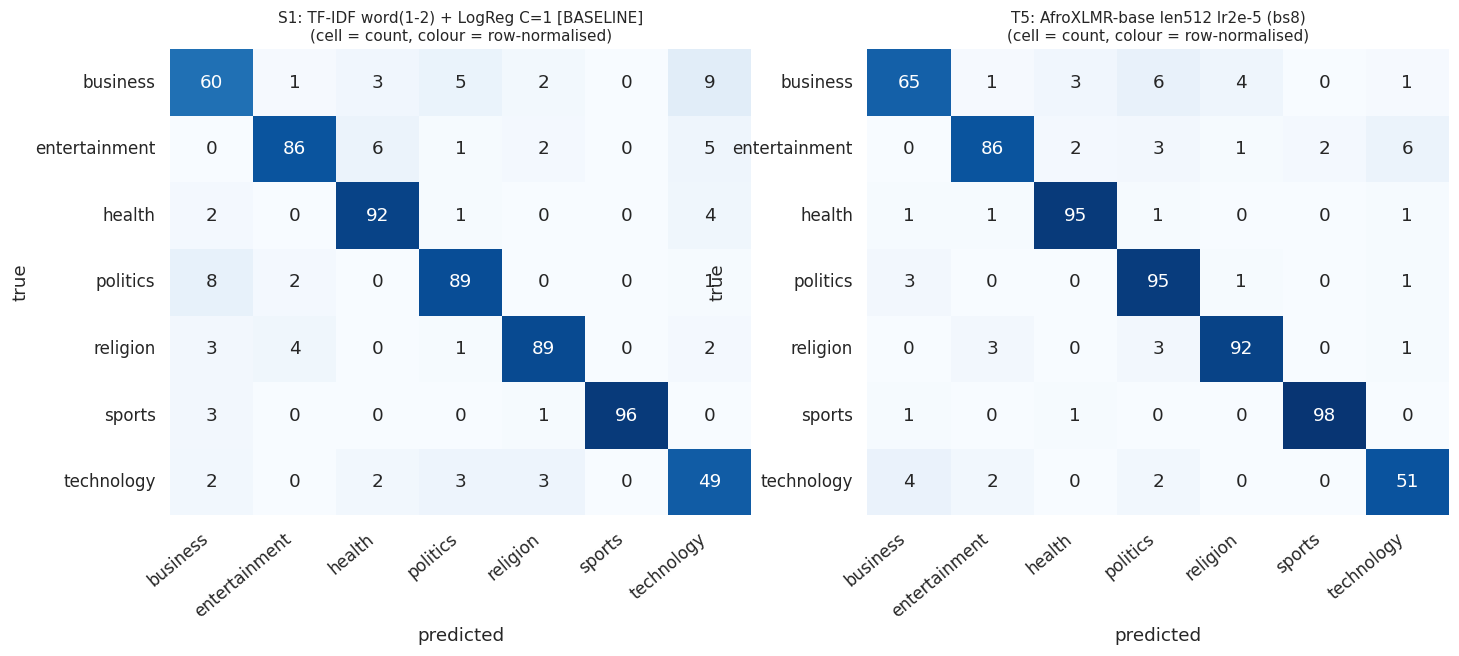

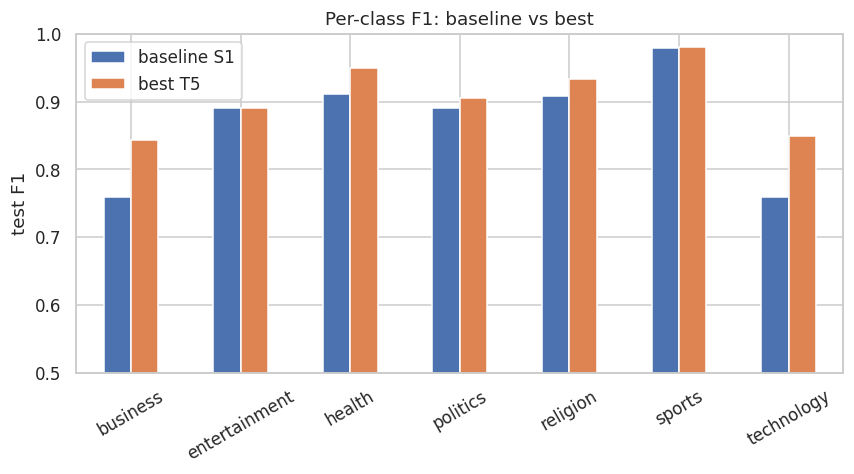

In [14]:
def name_of(eid): return res.loc[res.exp_id == eid, "name"].item()
for eid in dict.fromkeys([baseline_id, best_id]):
    print("=" * 80); print(f"{eid}: {name_of(eid)}  (TEST SET)"); print("=" * 80)
    print(classification_report(y_test, preds[eid]["test"], target_names=LABELS, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, eid in zip(axes, [baseline_id, best_id]):
    cm = confusion_matrix(y_test, preds[eid]["test"], labels=range(N_CLASSES))
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(f"{eid}: {name_of(eid)[:40]}\n(cell = count, colour = row-normalised)", fontsize=10)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
plt.savefig(f"{OUT_DIR}/fig_confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

f1_base = f1_score(y_test, preds[baseline_id]["test"], average=None); f1_best = f1_score(y_test, preds[best_id]["test"], average=None)
pc = pd.DataFrame({"baseline " + baseline_id: f1_base, "best " + best_id: f1_best}, index=LABELS)
pc.plot(kind="bar", figsize=(9, 4)); plt.ylim(0.5, 1.0); plt.ylabel("test F1"); plt.title("Per-class F1: baseline vs best"); plt.xticks(rotation=30)
plt.savefig(f"{OUT_DIR}/fig_per_class_f1.png", dpi=200, bbox_inches="tight"); plt.show()

## 10. Error analysis
Covers: most confused class pairs, most confident mistakes, error rate by article length, OOV rate of errors, baseline-vs-best agreement with an exact McNemar test, and the words the baseline relies on per class. Use the printed examples in your report and video.

In [15]:
err = test.copy()
err["pred_id"] = preds[best_id]["test"]; err["pred"] = err["pred_id"].map(id2label); err["true"] = err["category"]
err["correct"] = err["pred_id"] == err["label"]
err["confidence"] = preds[best_id]["proba"].max(1) if preds[best_id]["proba"] is not None else np.nan
err["snippet"] = err["text"].str.slice(0, 300)
wrong, right = err[~err.correct], err[err.correct]
print(f"Best model {best_id}: {len(wrong)} errors out of {len(err)} test articles ({len(wrong)/len(err):.1%})\n")

# 1) most confused pairs
pairs = pd.DataFrame(Counter(zip(wrong["true"], wrong["pred"])).most_common(10), columns=["(true, predicted)", "count"])
print("Most frequent confusions:"); display(pairs)

# 2) most confident mistakes (often label noise or genuinely ambiguous articles)
print("\nMost CONFIDENT mistakes:")
for _, r in wrong.sort_values("confidence", ascending=False).head(8).iterrows():
    print(f"- true={r['true']:<13} pred={r['pred']:<13} conf={r['confidence']:.2f} | {r['headline'][:110]}")
    print(f"    {r['snippet'][:200]}...")
wrong.drop(columns=["input"]).to_csv(f"{OUT_DIR}/misclassified_test_examples.csv", index=False)

# 3) a few clear successes
print("\nConfident CORRECT predictions:")
for _, r in right.sort_values("confidence", ascending=False).head(3).iterrows():
    print(f"- {r['true']:<13} conf={r['confidence']:.2f} | {r['headline'][:110]}")

Best model T5: 55 errors out of 637 test articles (8.6%)

Most frequent confusions:


,"(true, predicted)",count
0,"(business, politics)",6
1,"(entertainment, technology)",6
2,"(business, religion)",4
3,"(technology, business)",4
4,"(business, health)",3
5,"(entertainment, politics)",3
6,"(politics, business)",3
7,"(religion, politics)",3
8,"(religion, entertainment)",3
9,"(entertainment, sports)",2



Most CONFIDENT mistakes:
- true=business      pred=religion      conf=1.00 | Matakan kare kai daga haduran ababen hawa a Najeriya
    Dauda Ali Biu, muƙaddashin shugaban hukuma kiyaye aukuwar haɗura ta Najeriya, ya yi bayani game da tsare-tsaren hukumarsa game da yadda za su tunkari lokutan bukukuwan Kirsimeti da na sabuwar shekara....
- true=business      pred=religion      conf=1.00 | Asarar da Saudiyya ke yi saboda rashin mahajjata daga kasashen duniya
    Saudiyya na daga cikin manyan kasashen duniya da annobar cutar korona ta haifar da koma baya gahanyoyin samun kudaden shigarta. Saudiyya na samum ɗumbin kudaden shiga a lokutan ayyukan Hajji da Umara ...
- true=entertainment pred=health        conf=1.00 | Coronavirus: Mawaƙiya Madonna ta kamu da cutar
    Shahararriyar mawakiyar nan ta Amurka, Madonna, ta ce ta yi fama da cutar korona lokacin da ta yi tafiya zuwa wasu kasashen duniya. A sakon da ta wallafa ranar Laraba a Instagram, ta ce ta harbu da cu...
- true=business      pre

In [16]:
# 4) error rate by article length
bins, names = [0, 50, 150, 400, 10**6], ["<50 words", "50-150", "150-400", ">400"]
test["len_bucket"] = pd.cut(test["n_words"], bins=bins, labels=names)
rows = []
for eid in dict.fromkeys([baseline_id, best_id]):
    acc = (preds[eid]["test"] == y_test)
    rows.append(pd.Series(acc).groupby(test["len_bucket"].values).mean().rename(f"{eid} accuracy"))
len_tab = pd.concat(rows, axis=1); len_tab["n_articles"] = test["len_bucket"].value_counts()
print("Accuracy by article length:"); display(len_tab.round(3))

# 5) OOV rate: are errors linked to unseen vocabulary?
test["oov"] = [np.mean([t not in train_vocab for t in toks]) if toks else 0 for toks in test_tok]
print(f"\nMean OOV rate  correct: {test.loc[err.correct.values, 'oov'].mean():.3%} | wrong: {test.loc[~err.correct.values, 'oov'].mean():.3%}")

# 6) baseline vs best: agreement + exact McNemar test
a, b = preds[baseline_id]["test"] == y_test, preds[best_id]["test"] == y_test
both, only_base, only_best, neither = (a & b).sum(), (a & ~b).sum(), (~a & b).sum(), (~a & ~b).sum()
print(f"\nBoth correct: {both} | only baseline: {only_base} | only best: {only_best} | both wrong: {neither}")
if baseline_id != best_id and (only_base + only_best) > 0:
    p = binomtest(int(min(only_base, only_best)), int(only_base + only_best), 0.5).pvalue
    print(f"Exact McNemar p-value = {p:.4f}  ->  difference is {'statistically significant' if p < 0.05 else 'NOT statistically significant'} at 0.05")

# 7) what the baseline relies on (interpretability)
vec, clf = objects[baseline_id]; feats = np.array(vec.get_feature_names_out())
print("\nTop TF-IDF features per class (baseline):")
for k, lab in enumerate(LABELS):
    print(f"  {lab:<14}", ", ".join(feats[np.argsort(clf.coef_[k])[-8:][::-1]]))

Accuracy by article length:


,S1 accuracy,T5 accuracy,n_articles
<50 words,0.818,0.909,44
50-150,0.911,0.911,90
150-400,0.907,0.931,216
>400,0.861,0.902,287



Mean OOV rate  correct: 1.881% | wrong: 2.578%

Both correct: 536 | only baseline: 25 | only best: 46 | both wrong: 30
Exact McNemar p-value = 0.0170  ->  difference is statistically significant at 0.05

Top TF-IDF features per class (baseline):
  business       tattalin, naira, farashin, man, kudin, dala, arzikin, fetur
  entertainment  fim, fina, waƙar, waka, kannywood, sarauniya, hausa, finan
  health         cutar, lafiya, da cutar, coronavirus, likitoci, lafiyar, kamuwa, kamuwa da
  politics       jam, iyyar, jam iyyar, zaben, apc, gwamnan, takarar, shugaban
  religion       musulunci, sheikh, addinin, malamin, musulmi, malamanku, musulmai, san malamanku
  sports         wasan, gasar, wasa, buga, kofin, dan wasan, kwallon, dan
  technology     kamfanin, amfani da, amfani, intanet, fasahar, manhajar, fasaha, amurka


## 11. Save the model, generate the Gradio app, and package results

In [17]:
# environment info for the report
env = {"python": platform.python_version(), "torch": torch.__version__, "device": str(DEVICE),
       "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None, "seed": SEED}
try:
    import transformers, sklearn; env.update(transformers=transformers.__version__, sklearn=sklearn.__version__)
except Exception: pass
json.dump(env, open(f"{OUT_DIR}/environment.json", "w"), indent=2); print(env)

APP = """import gradio as gr, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_ID = "best_model"   # local folder, or a Hugging Face Hub id such as "your-username/hausa-news-classifier"
MAX_LEN = __MAXLEN__
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID).eval()

def predict(headline, text):
    enc = tok((headline or "") + ". " + (text or ""), truncation=True, max_length=MAX_LEN, return_tensors="pt")
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits, -1)[0]
    return {model.config.id2label[i]: float(p) for i, p in enumerate(probs)}

demo = gr.Interface(fn=predict,
    inputs=[gr.Textbox(label="Headline (Hausa)"), gr.Textbox(label="Article text (Hausa)", lines=8)],
    outputs=gr.Label(num_top_classes=7, label="Predicted topic"),
    title="Hausa News Topic Classifier",
    description="Fine-tuned on MasakhaNEWS (Hausa). Categories: business, entertainment, health, politics, religion, sports, technology.")
demo.launch()
"""
if BEST_TR["exp_id"] is not None:
    open("app.py", "w").write(APP.replace("__MAXLEN__", str(BEST_TR["max_len"])))
    open("requirements.txt", "w").write("gradio\ntorch\ntransformers\nsentencepiece\n")
    print(f"Deployment files written (app.py, requirements.txt). Best fine-tuned model: {BEST_TR['exp_id']} "
          f"({BEST_TR['model_name']}, max_len={BEST_TR['max_len']}) saved in ./best_model")
else:
    print("No fine-tuned Transformer saved (GPU run needed) -> no app.py generated.")

{'python': '3.13.15', 'torch': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4', 'seed': 42, 'transformers': '5.18.0', 'sklearn': '1.6.1'}
Deployment files written (app.py, requirements.txt). Best fine-tuned model: T5 (Davlan/afro-xlmr-base, max_len=512) saved in ./best_model


In [18]:
# quick demo on 5 random test articles with the saved fine-tuned model
if BEST_TR["exp_id"] is not None:
    tok_d = AutoTokenizer.from_pretrained("best_model")
    mdl_d = AutoModelForSequenceClassification.from_pretrained("best_model").to(DEVICE).eval()
    def predict_text(headline, text):
        enc = tok_d(headline + ". " + text, truncation=True, max_length=BEST_TR["max_len"], return_tensors="pt").to(DEVICE)
        with torch.no_grad(): p = torch.softmax(mdl_d(**enc).logits, -1)[0].cpu().numpy()
        return {id2label[i]: float(v) for i, v in enumerate(p)}
    for _, r in test.sample(5, random_state=1).iterrows():
        out = predict_text(r["headline"], r["text"]); top = max(out, key=out.get)
        print(f"true={r['category']:<13} pred={top:<13} conf={out[top]:.2f} | {r['headline'][:90]}")
    del mdl_d; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

true=entertainment pred=entertainment conf=1.00 | Yadda matan Sudan Hausawa ke taron shan gahawa
true=technology    pred=technology    conf=1.00 | Yadda CIA ke amfani da ruwa wajen yi wa jama’a tambayoyi
true=religion      pred=religion      conf=1.00 | Abdulrahman Muhammad Auwal: 'Wasiyyar da mahaifina Sheikh Albaniy ya bar mana'
true=religion      pred=religion      conf=1.00 | Ku San Malamanku tare da Malama Zainab Ja'afar Mahmud Adam
true=sports        pred=sports        conf=1.00 | Chelsea 2-4 Arsenal: Gunners ta je ta ragargaji Chelsea a Stamford Bridge


In [19]:
# package everything for download
with zipfile.ZipFile("results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in os.listdir(OUT_DIR): z.write(os.path.join(OUT_DIR, f), f)
    for f in ("app.py", "requirements.txt"):
        if os.path.exists(f): z.write(f, f)
print("Created results.zip with:", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download("results.zip")
    if SAVE_MODEL_ZIP and os.path.isdir("best_model"):
        shutil.make_archive("best_model", "zip", "best_model"); files.download("best_model.zip")
except ImportError:
    pass

Created results.zip with: ['environment.json', 'experiment_results.csv', 'fig_class_distribution.png', 'fig_confusion_matrices.png', 'fig_experiment_comparison.png', 'fig_learning_curves.png', 'fig_length_distribution.png', 'fig_per_class_f1.png', 'misclassified_test_examples.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
   from huggingface_hub import notebook_login, HfApi
   notebook_login()
   api = HfApi()
   api.create_repo("hausa-news-classifier", exist_ok=True)
   api.upload_folder(folder_path="best_model", repo_id="dmahe09/hausa-news-classifier")

HfHubHTTPError: Client error '401 Unauthorized' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6ad5e49e-5cedc2ba5b95c08e2e08cb4f;dde605fc-eb8c-48cd-9e89-117a4f9a1cc8)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/401

Invalid username or password.